In [1]:
from itertools import product
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


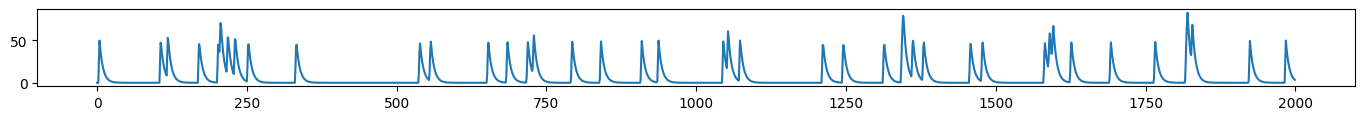

In [2]:
n_timepoints = 1_000
n_components = 1
interp_factor = 2

clean = np.zeros((n_components, n_timepoints * interp_factor))

x = 0
a = 0.7

b = 0

firing_prop = 0.05

spikes = list()

for i in range(n_components):
    spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

for c_ix in range(n_components):
    for i in range(2, n_timepoints):
        clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (50 * spikes[c_ix][i])

    x_ = np.arange(0, n_timepoints * interp_factor)
    xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
    clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

n_timepoints *= 2

fig = plt.figure(figsize=(17, 1))
for i in range(n_components):
    plt.plot(clean[i])

In [3]:
noise = 20

In [4]:
n_pixels = 3

series = list()

for i in range(n_components):
    for j in range(n_pixels):
        series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))

series = np.vstack(series)

<Axes: >

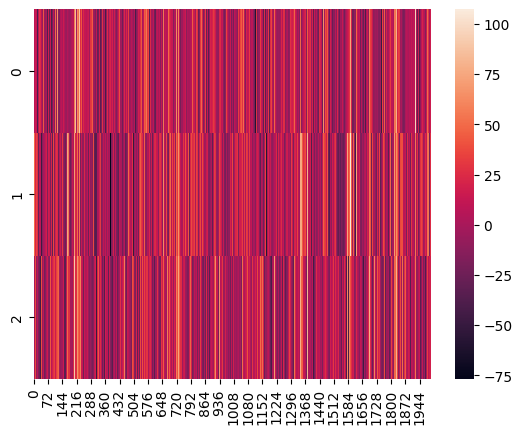

In [5]:
sns.heatmap(series)

In [6]:
series[-1] = np.random.normal(scale=noise, size=n_timepoints)
series[-1] -= series[-1].mean()

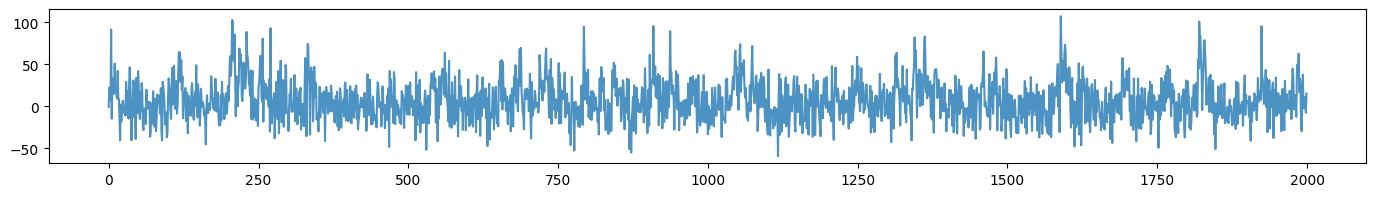

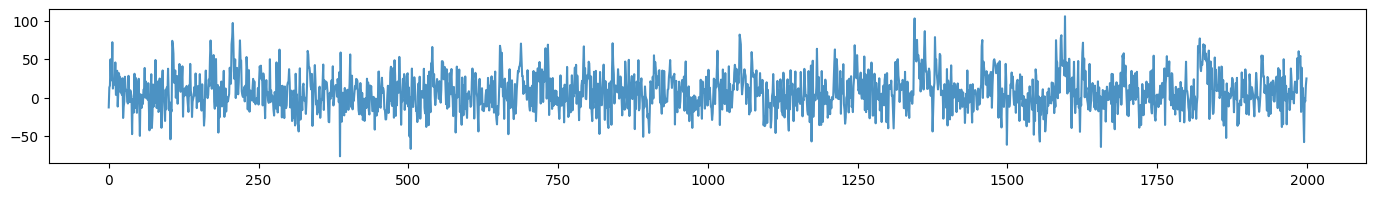

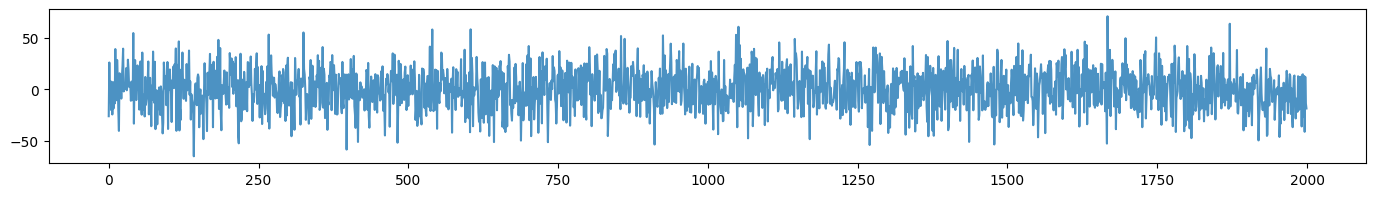

In [7]:
for i in range(n_pixels * n_components):
    fig = plt.figure(figsize=(17, 2))
    plt.plot(series[i], alpha=0.8)
    plt.show()

# plt.plot(clean, c="k", alpha=0.3)

In [8]:
series.mean(axis=1)

array([ 7.26028454e+00,  7.62281881e+00, -4.26325641e-17])

In [9]:
series.std(axis=1)

array([23.81062053, 24.07854967, 20.00335111])

In [10]:
series.ptp(axis=1)

array([166.64544983, 182.76600538, 136.70307684])

In [11]:
from scipy import linalg

In [12]:
import seaborn as sns

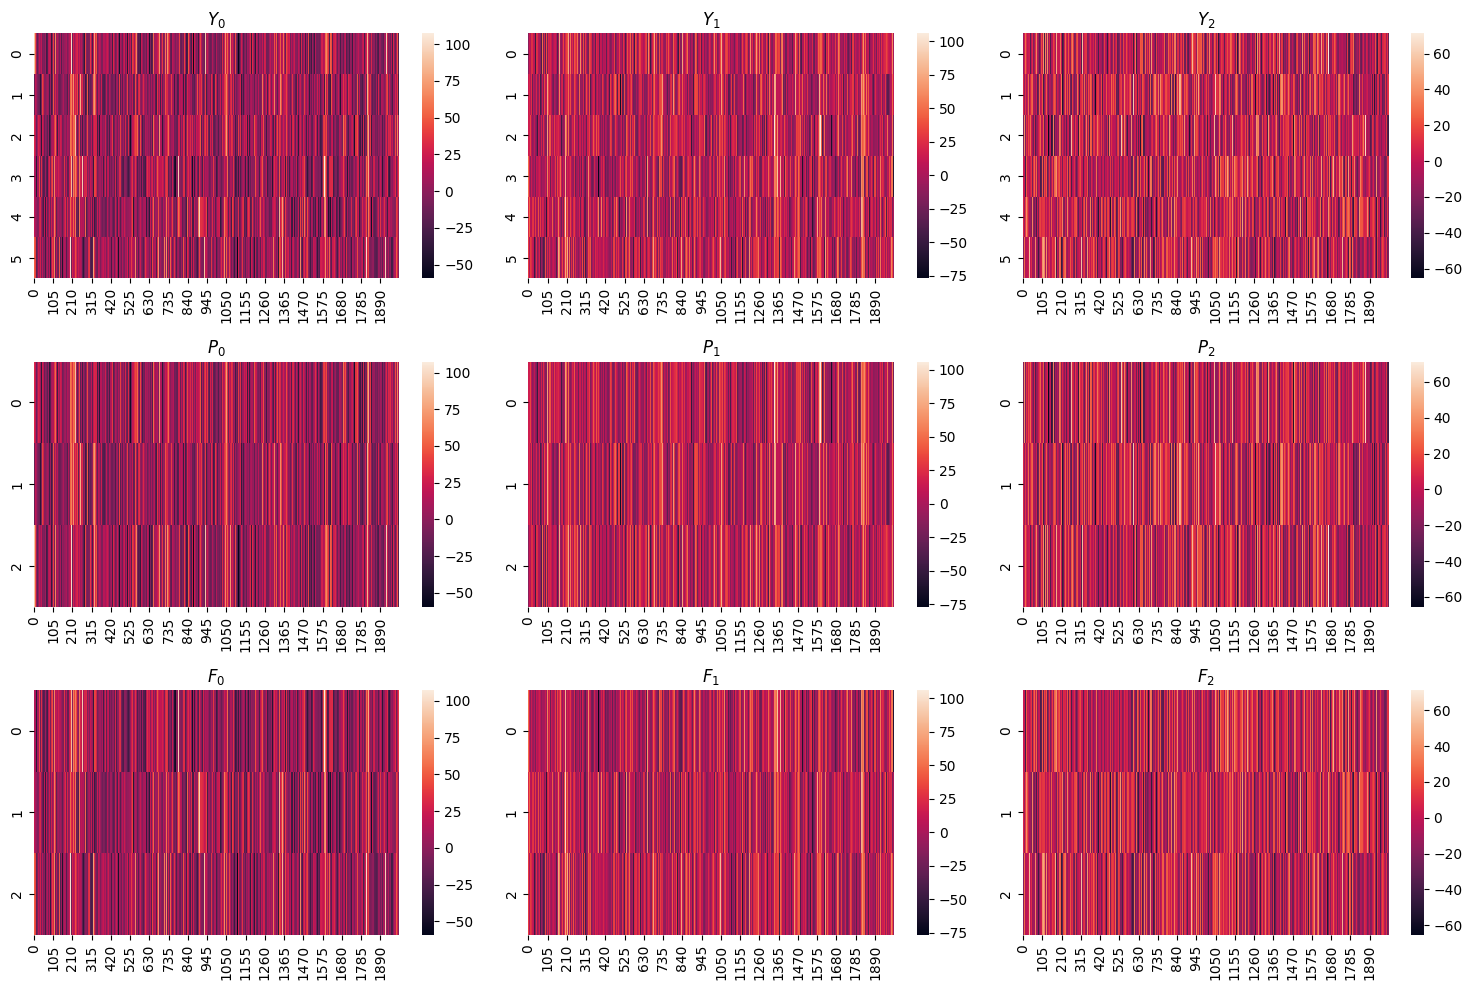

In [13]:
center = 100
w = 6

Ys = list()
Ps = list()
Fs = list()

fig, axs = plt.subplots(3, n_pixels, figsize=(15, 10))

for i in range(n_pixels):
    y = linalg.hankel(series[i, :w], series[i, w:])
    p = np.flipud(y[:int(w / 2)])
    f = y[int(w / 2):]

    Ys.append(y)
    Ps.append(p)
    Fs.append(f)
        
    sns.heatmap(y, ax=axs[0, i])
    axs[0, i].set_title(f"$Y_{i}$")

    sns.heatmap(p, ax=axs[1, i])
    axs[1, i].set_title(f"$P_{i}$")

    sns.heatmap(f, ax=axs[2, i])
    axs[2, i].set_title(f"$F_{i}$")

plt.tight_layout()

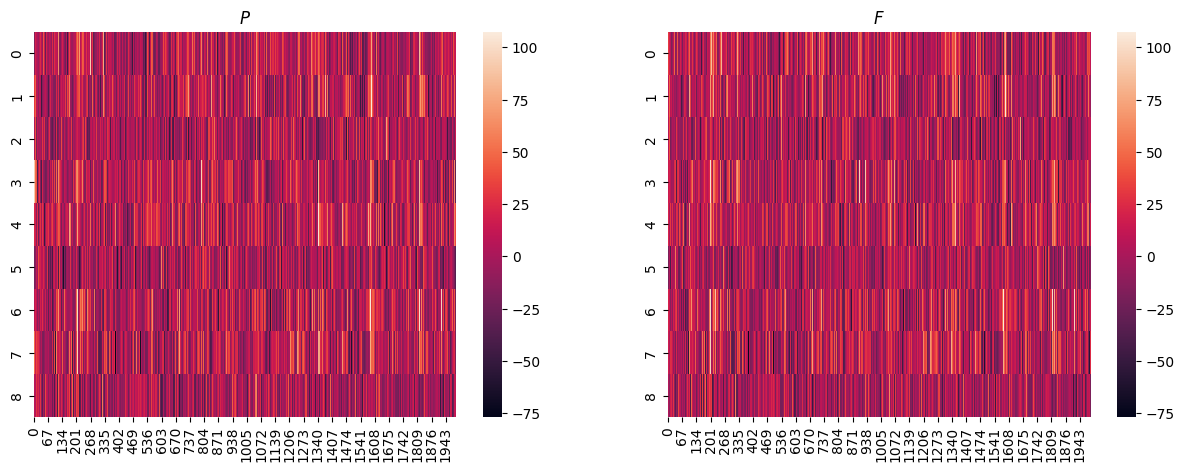

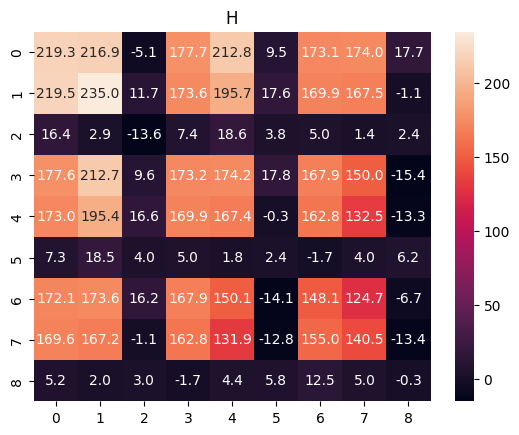

In [14]:
P_F_shape = (int(w / 2) * n_pixels, n_timepoints - w)

P = np.zeros(P_F_shape)
F = np.zeros(P_F_shape)

for i in range(n_pixels):
    P[i::n_pixels] = Ps[i]
    F[i::n_pixels] = Fs[i]

fig, axs = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(P, ax=axs[0])
axs[0].set_title(f"$P$")

sns.heatmap(F, ax=axs[1])
axs[1].set_title(f"$F$")
plt.show()

H = (F @ P.T) / P.shape[1]

sns.heatmap(H, annot=True, fmt="0.1f")
plt.title("H")
plt.show()

In [15]:
from itertools import product

In [16]:
list(product(*[range(0, int(w / 2) + n_pixels + 1, n_pixels)]*2))

[(0, 0), (0, 3), (0, 6), (3, 0), (3, 3), (3, 6), (6, 0), (6, 3), (6, 6)]

In [17]:
Hp = np.zeros((int(w / 2)**2, n_pixels**2))

for row_ix, (block_i, block_j) in enumerate(product(*[range(0, int(w / 2) * n_pixels, n_pixels)]*2)):
    Hp[row_ix] = H.T[block_i:block_i + n_pixels, block_j:block_j + n_pixels].ravel()

<Axes: >

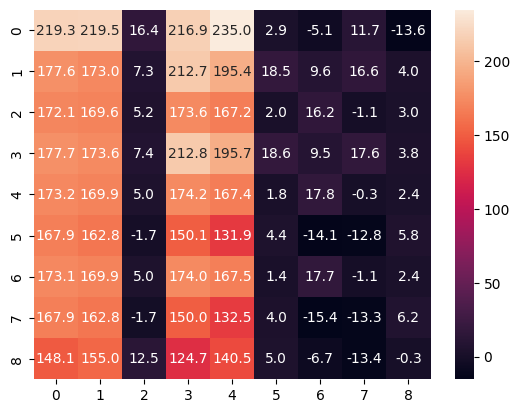

In [18]:
sns.heatmap(Hp, annot=True, fmt="0.1f")

In [19]:
u, s, v = linalg.svd(Hp)

Text(0.5, 1.0, 'V')

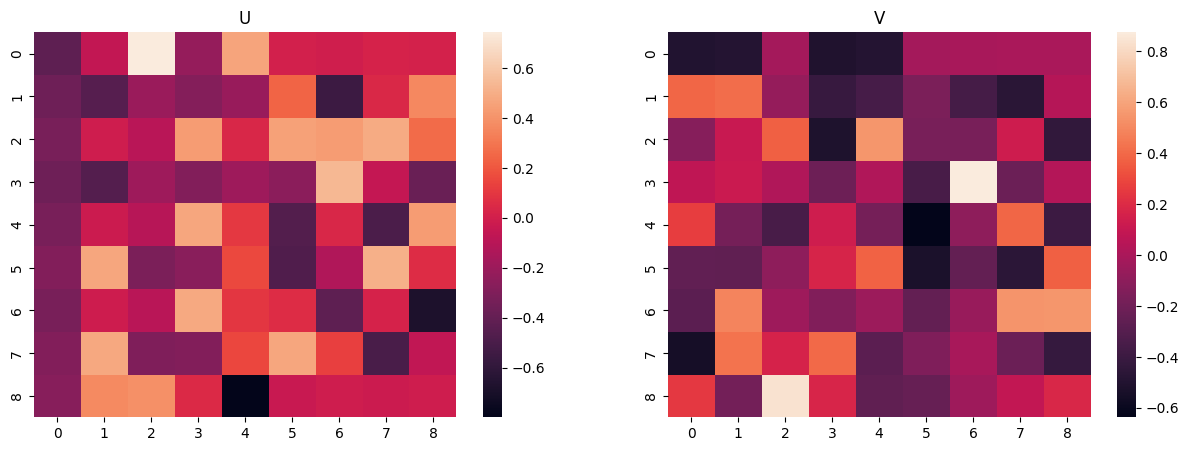

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(u, ax=axs[0])
axs[0].set_title("U")
sns.heatmap(v, ax=axs[1])
axs[1].set_title("V")

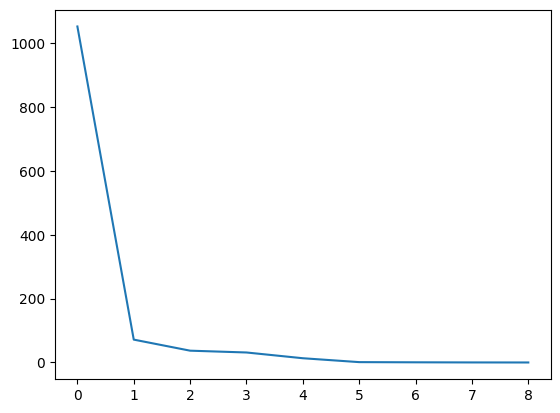

In [21]:
plt.plot(s)

Text(0.5, 1.0, '$V^r$')

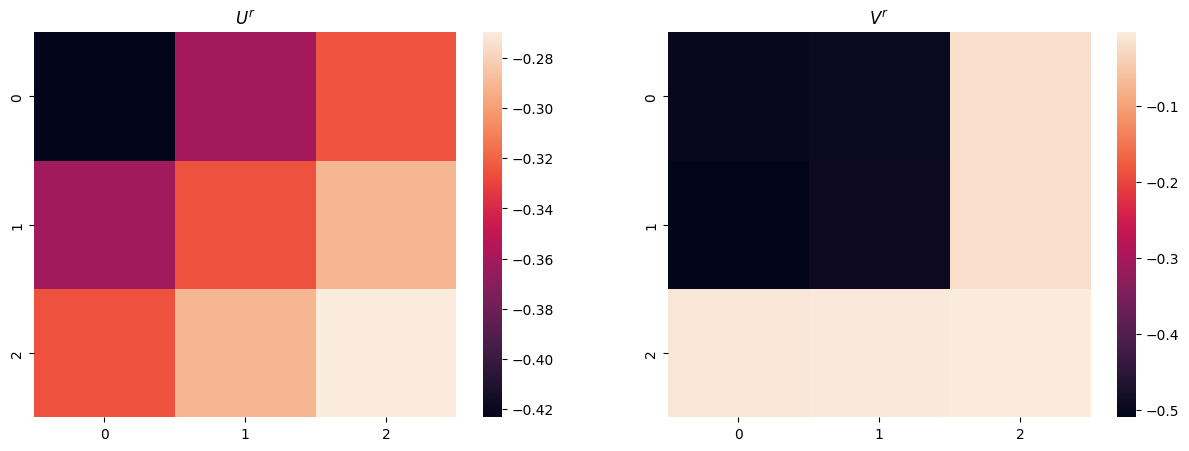

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
u_r = u[:, 0].reshape(int(w / 2), int(w / 2))
sns.heatmap(u_r, ax=axs[0])
axs[0].set_title("$U^r$")

v_r = v[0].reshape(n_pixels, n_pixels)
sns.heatmap(v_r, ax=axs[1])
axs[1].set_title("$V^r$")

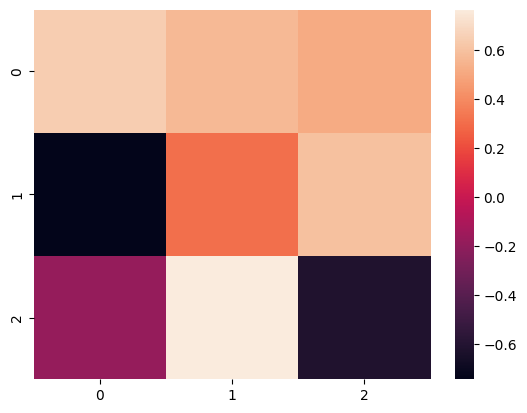

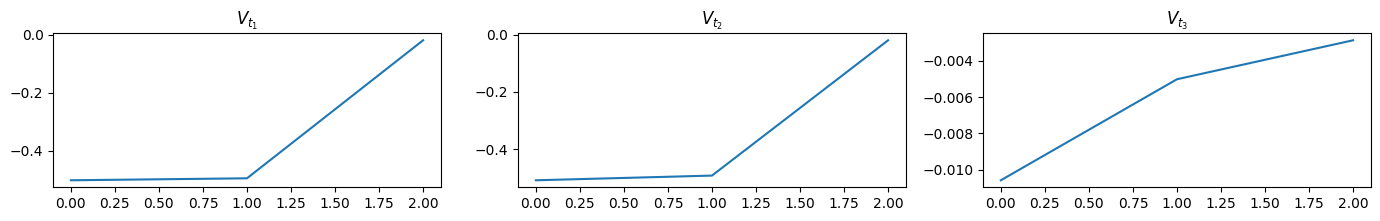

In [23]:
u_t, s_t, v_t = linalg.svd(u_r)

sns.heatmap(v_t)
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(17, 2))

for i in range(3):
    axs[i].plot(v_r[i])
    axs[i].set_title(f"$V_{{t_{i + 1}}}$")
    
plt.show()

In [24]:
u_s, s_s, v_s = linalg.svd(v_r)

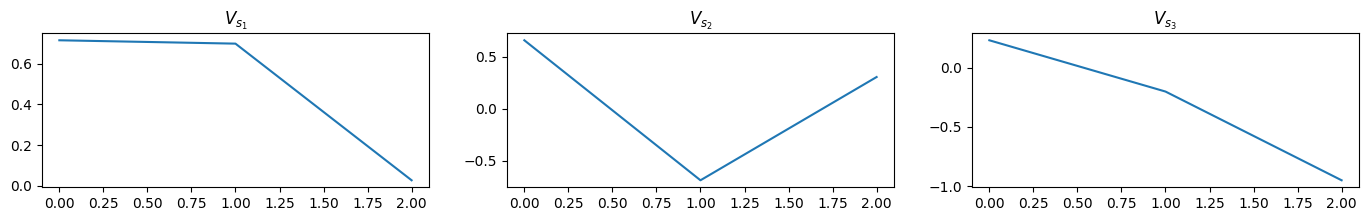

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(17, 2))

for i in range(3):
    axs[i].plot(v_s[i])
    axs[i].set_title(f"$V_{{s_{i + 1}}}$")

plt.show()

In [26]:
v_s[0]

array([0.7150654 , 0.69854892, 0.02666227])

In [27]:
filt = np.kron(v_s[0], v_t[0])

In [28]:
filt.shape

(9,)

In [29]:
P.shape

(9, 1994)

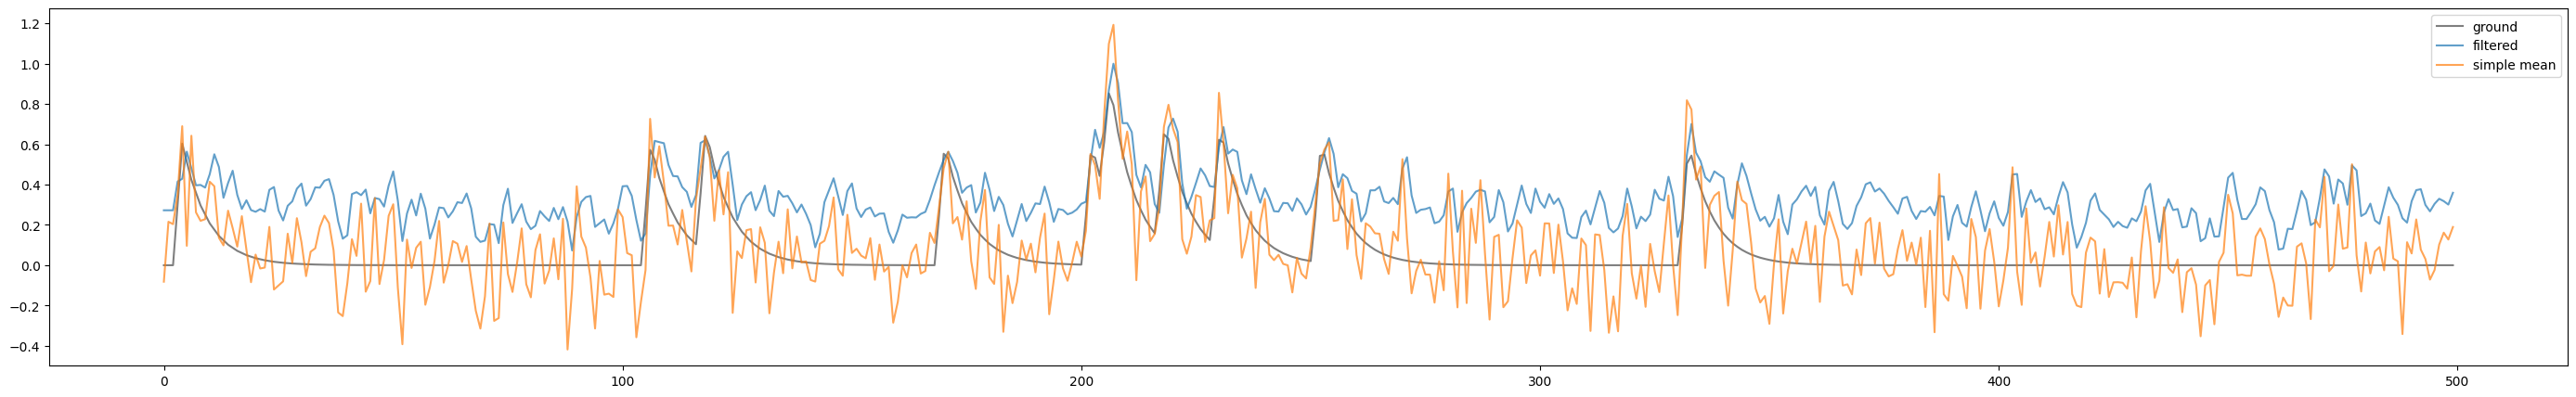

In [30]:
filtered = np.zeros(shape=(n_timepoints - int(w / 2)))
filtered[int(w / 2):] = filt @ P


filtered -= filtered.min()
filtered /= filtered.max()

indices = slice(0, 500)
fig = plt.figure(figsize=(35, 5))
plt.plot(clean[0, indices] / clean.max(), label="ground", alpha=0.5, c="k")
plt.plot(filtered[indices], label="filtered", alpha=0.7)
plt.plot(series[:-1].mean(axis=0)[indices] / clean.max(), alpha=0.7, label="simple mean")
plt.legend()
plt.show()